In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import logging
import random
import os

import mlflow
import matplotlib.pyplot as plt
from networkx import number_weakly_connected_components
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators import NoiseLevel, SimulationResult, run_gnw

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

Check if MLFlow connects correctly

In [2]:
print(os.getenv("MLFLOW_TRACKING_URI"))

https://mlflow.cropresilience.org


In [3]:
mlflow.set_experiment("Halcyon sandbox experiment")
mlflow.set_experiment_tag("Tool name", "HALCYON") 

# Input data

## Simulating

In [ ]:
for noise in NoiseLevel:
    print(noise)

NoiseLevel.LOW
NoiseLevel.MEDIUM
NoiseLevel.HIGH


2026-03-12 12:01:16,964 - INFO - Generating network
2026-03-12 12:01:17,757 - INFO - Loading specified settings: ../setting_files/gnw_low_noise.txt
Done
Start network creation of type MODULAR_SCALEFREE
Removing autoregulatory interactions from my_network
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: ~(Node_4*Node_3) + (Node_2)
my_network: Node_1: ~(Node_9*Node_5*Node_13~Node_0)
my_network: Node_2: (Node_4*Node_7) + (Node_1~Node_3) + (Node_0)
my_network: Node_3: (Node_2*Node_4) + (Node_7*Node_0)
my_network: Node_4: ~(Node_3*Node_7~Node_0) + (Node_2)
my_network: Node_5: (Node_11) + ~(Node_2*Node_1)
my_network: Node_6: ~(Node_9) + ~(Node_5) + ~(Node_12) + ~(Node_1)
my_network: Node_7: (Node_4*Node_0) + ~(Node_8~Node_3)
my_network: Node_8: ~(Node_2~Node_0) + (Node_7)
my_network: Node_9: ~(Node_1*Node_6)
my_network: Node_10: ~(Node_1)
my_network: Node_11: ~(Node_5) + ~(Node_1)
my_network: Node_12: (Node_9)
my_network: Node_13: ~(Node_1~Node_

🏃 View run dataset_genes20_sparsity0.1_nr_modules2_noiseLOW at: https://mlflow.cropresilience.org/#/experiments/3/runs/f5d188412b3643c0956abb757fb9eeb4
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


2026-03-12 12:01:43,795 - INFO - Loading specified settings: ../setting_files/gnw_medium_noise.txt
Done
Start network creation of type MODULAR_SCALEFREE
Removing autoregulatory interactions from my_network
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: ~(Node_4*Node_3) + (Node_2)
my_network: Node_1: ~(Node_9*Node_5*Node_13~Node_0)
my_network: Node_2: (Node_4*Node_7) + (Node_1~Node_3) + (Node_0)
my_network: Node_3: (Node_2*Node_4) + (Node_7*Node_0)
my_network: Node_4: ~(Node_3*Node_7~Node_0) + (Node_2)
my_network: Node_5: (Node_11) + ~(Node_2*Node_1)
my_network: Node_6: ~(Node_9) + ~(Node_5) + ~(Node_12) + ~(Node_1)
my_network: Node_7: (Node_4*Node_0) + ~(Node_8~Node_3)
my_network: Node_8: ~(Node_2~Node_0) + (Node_7)
my_network: Node_9: ~(Node_1*Node_6)
my_network: Node_10: ~(Node_1)
my_network: Node_11: ~(Node_5) + ~(Node_1)
my_network: Node_12: (Node_9)
my_network: Node_13: ~(Node_1~Node_6)
my_network: Node_14: (Node_5)
my_network: Node

🏃 View run dataset_genes20_sparsity0.1_nr_modules2_noiseMEDIUM at: https://mlflow.cropresilience.org/#/experiments/3/runs/24de502100804e0fa97f64155c01146e
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


2026-03-12 12:01:58,849 - INFO - Loading specified settings: ../setting_files/gnw_high_noise.txt
Done
Start network creation of type MODULAR_SCALEFREE
Removing autoregulatory interactions from my_network
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: ~(Node_4*Node_3) + (Node_2)
my_network: Node_1: ~(Node_9*Node_5*Node_13~Node_0)
my_network: Node_2: (Node_4*Node_7) + (Node_1~Node_3) + (Node_0)
my_network: Node_3: (Node_2*Node_4) + (Node_7*Node_0)
my_network: Node_4: ~(Node_3*Node_7~Node_0) + (Node_2)
my_network: Node_5: (Node_11) + ~(Node_2*Node_1)
my_network: Node_6: ~(Node_9) + ~(Node_5) + ~(Node_12) + ~(Node_1)
my_network: Node_7: (Node_4*Node_0) + ~(Node_8~Node_3)
my_network: Node_8: ~(Node_2~Node_0) + (Node_7)
my_network: Node_9: ~(Node_1*Node_6)
my_network: Node_10: ~(Node_1)
my_network: Node_11: ~(Node_5) + ~(Node_1)
my_network: Node_12: (Node_9)
my_network: Node_13: ~(Node_1~Node_6)
my_network: Node_14: (Node_5)
my_network: Node_1

🏃 View run dataset_genes20_sparsity0.1_nr_modules2_noiseHIGH at: https://mlflow.cropresilience.org/#/experiments/3/runs/a149e95c37394986a00059a4ec4e80d5
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


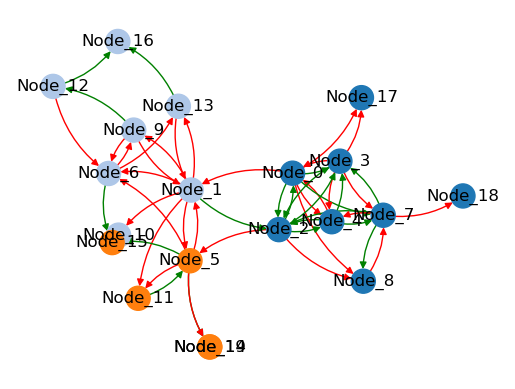

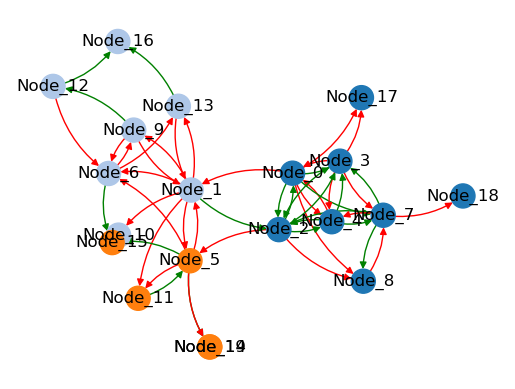

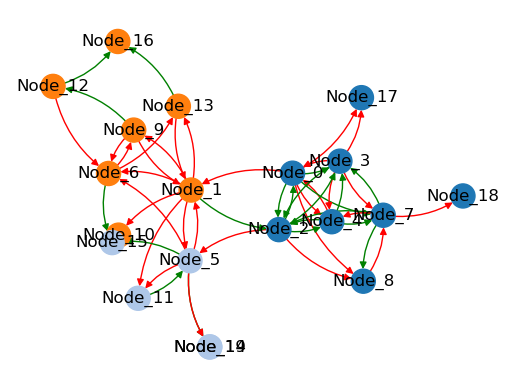

In [7]:
# nr_genes_list =   [20, 50, 100, 500]
# nr_modules_list = [2,  5,  10,  50 ]
nr_genes_list =   [20]
nr_modules_list = [2]
sparsity_list = [0.1]
keep_self_interactions = False

out_path = Path("../data/datasets_for_mlflow_logging") 
settings_dir = Path("../setting_files")

sim_outputs: list[SimulationResult] = []
for nr_genes, nr_modules in zip(nr_genes_list, nr_modules_list): 
    for sparsity in sparsity_list:
        for noise in NoiseLevel:
            generated_data_path = out_path / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}_noise_{noise.name}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_output = run_gnw(
                settings_dir=settings_dir,
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
                noise_level=noise,
                keep_self_interactions=keep_self_interactions,
            )

            sim_output.network.do_clustering()
            assert number_weakly_connected_components(sim_output.network._graph) == 1, "The generated network is not fully connected."
            
            sim_output.network.plot()
            fig_path = generated_data_path / "network_plot.png"
            plt.savefig(fig_path)

            sim_output.save_to_pkl(generated_data_path / "simulation_result.pkl")
            
            with mlflow.start_run(run_name=f"dataset_genes{nr_genes}_sparsity{sparsity}_nr_modules{nr_modules}_noise{noise.name}"):
                mlflow.set_tag("run_type", "dataset")
                mlflow.log_params({
                    "nr_genes": nr_genes,
                    "sparsity": sparsity,
                    "num_modules": nr_modules,
                    "noise_level": noise.name,
                    "seed": seed,
                })
                mlflow.log_artifacts(generated_data_path, artifact_path="dataset")
                

# All files have now been logged to MLFlow

To see how to train data look into the `scripts/train.py` 